# Interdot detector with a U-Net, then a U-Net that survives unseen artefacts

Input: a raw charge-stability diagram (150 × 150 px). Output: a binary mask of its interdot
transitions (the **sticks**). This notebook follows the two deep-learning detectors of
challenge 1, in the order they were built, each one answering the failure of the previous one:

1. **U-Net** trained on an infinite simulator generator, with a log-uniform contrast law so that
   faint sticks (the regime of challenge 2) are well represented;
2. **U-Net LOFO**: the same U-Net behind a parameter-free physical preprocessing (`PhysInput`),
   trained on 8 randomized laboratory-artefact families, and tested **leave-one-family-out**:
   every artefact is scored by a model that never saw it.

Each section shows the data, what the step does, and the measurement that motivated the next
one. The U-Net is run live on the 200 versioned test scenes; the LOFO numbers come from the
22 training runs stored in `results/lofo/` (their checkpoints are not versioned).

## 0. Setup

`clean.npz` holds the 200 test scenes of the robustness suite (official generator, default
config). `unet_lowsnr.pt` is the frozen U-Net (EMA weights in float16 + its threshold, chosen on
val). `score` is the scorer used for every number of the README.

In [1]:
import json
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import ListedColormap
from scipy.ndimage import label as ndlabel

ML = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "detection").exists())
sys.path.insert(0, str(ML))  # stage1_unet/, holds the `detection` package

from detection.evalsets import predict, score
from detection.export_dl import load
from detection.models import PhysInput, build_model, n_params
from detection.robustness import LEVELS, perturb, set_name

RES = ML / "results"
DEV = torch.device("cpu")
torch.set_num_threads(8)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10})


class Scenes:
    "The minimal interface of `detection.evalsets.EvalSet` that `score` needs."

    def __init__(self, images, masks, sticks, name):
        self.images, self.masks, self.sticks, self.name = images, masks, sticks, name

    def __len__(self):
        return len(self.images)


z = np.load(ML / "robustness_suite/clean.npz")
masks = np.unpackbits(z["masks"], axis=-1, count=int(z["shape"][-1])).astype(np.uint8)
sticks = [json.loads(l)["sticks"] for l in open(ML / "robustness_suite/clean_sticks.jsonl")]
test = Scenes(z["images"].astype(np.float32), masks, sticks, "clean")

unet, THR = load(ML / "models/unet_lowsnr.pt")
probs = predict(unet, test.images, DEV)
print(f"{len(test)} test scenes, U-Net {n_params(unet) / 1e6:.2f} M parameters, threshold {THR}")


def panel(ax, img, title, mask=None, color="tab:red", **kw):
    "Draw an image, with an optional mask painted over it."
    im = ax.imshow(img, **{"cmap": "gray", **kw})
    if mask is not None:
        ax.imshow(np.ma.masked_where(~mask, mask), cmap=ListedColormap([color]), alpha=0.7)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    return im


def obj_f1(p, scenes, thr=THR):
    return score(p, scenes, thr=thr)["obj_f1"]

200 test scenes, U-Net 1.93 M parameters, threshold 0.55


## 1. The data and the metric

A stick is a short segment at about 45°, 4 to 8 px long and under 2 px wide: 0.35 % of the
pixels. Its contrast |i| is drawn by the generator between 1 and 33 noise σ, on a background of
white noise plus horizontal stripes.

The official mask is a blurred rectangle thresholded at 0.5. It is **fragmented** (count the
connected pieces below) and its width depends on how the rectangle falls on the pixel grid, not
on the physics. Dice against it partly measures pixelization luck. We therefore select and
report on:

- **obj F1**: a stick is found if a predicted pixel lies within len/2 + 1 px of its centre, and a
  predicted blob is correct if its centroid lies within len/2 + 2 px of a stick — *did I find the
  interdots?* (the quantity challenge 2 needs);
- **tol F1**: pixel F1 with a ±1 px tolerance — *is the trace in the right place?*

The threshold is chosen on val by (obj F1 + tol F1) / 2, then frozen.

contrast |i| of the test sticks: median 18.9 σ, 8% below 4 σ


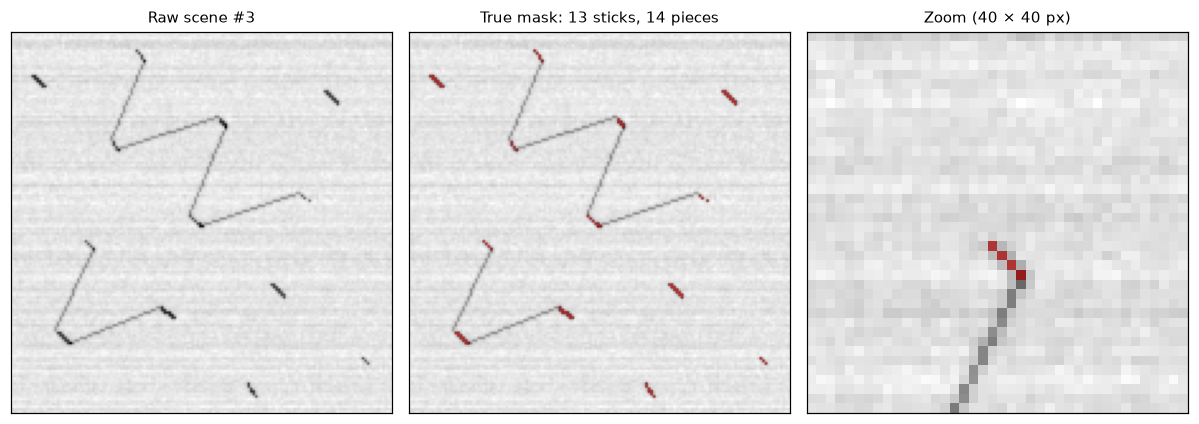

In [2]:
k = 3
img, m = test.images[k], test.masks[k].astype(bool)
r, c = slice(60, 100), slice(10, 50)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
panel(axes[0], img, f"Raw scene #{k}")
panel(axes[1], img, f"True mask: {len(sticks[k])} sticks, {ndlabel(m, np.ones((3, 3)))[1]} pieces", m)
panel(axes[2], img[r, c], "Zoom (40 × 40 px)", m[r, c])
plt.tight_layout()

amp = np.array([abs(s["intensity"]) for sc in sticks for s in sc])
print(f"contrast |i| of the test sticks: median {np.median(amp):.1f} σ, {np.mean(amp < 4):.0%} below 4 σ")

## 2. The U-Net

**Why this architecture.** Sticks are sub-pixel and sparse: the useful information is local and
the output must be full resolution. A convolutional encoder–decoder with skip connections has
exactly this bias: 3 poolings (receptive field of a few tens of pixels, enough to see a stick and
its neighbourhood) and skips that carry the 1-px detail back to the output.

In [3]:
net = build_model("unet").net
x = torch.zeros(1, 1, 152, 152)
print("input", tuple(x.shape))
skips = [net.inc(x)]
print(f"  inc        -> {tuple(skips[-1].shape)}")
for i, d in enumerate(net.downs):
    skips.append(d(torch.nn.functional.max_pool2d(skips[-1], 2)))
    print(f"  down {i + 1}     -> {tuple(skips[-1].shape)}")
y = skips.pop()
for i, (up, dec) in enumerate(zip(net.ups, net.dec)):
    y = dec(torch.cat([up(y), skips.pop()], 1))
    print(f"  up {i + 1} + skip -> {tuple(y.shape)}")
print(f"  out (1x1)  -> {tuple(net.out(y).shape)}   (logit per pixel)")
print(f"{n_params(net):,} parameters")

input (1, 1, 152, 152)
  inc        -> (1, 32, 152, 152)
  down 1     -> (1, 64, 76, 76)
  down 2     -> (1, 128, 38, 38)
  down 3     -> (1, 256, 19, 19)
  up 1 + skip -> (1, 128, 38, 38)
  up 2 + skip -> (1, 64, 76, 76)
  up 3 + skip -> (1, 32, 152, 152)
  out (1x1)  -> (1, 1, 152, 152)   (logit per pixel)
1,926,433 parameters


## 3. Training on an infinite generator

**Data.** Blur is linear, so a scene is `i · template + blur(σ_pix · white + σ_h · stripes)`.
30 000 geometries (template + soft label) are precomputed once; the contrast i and the noise are
drawn on the GPU at every batch. No image is seen twice: the only possible overfit is on the
geometries, and the measured pool − val gap stays under 0.008.

**Loss and augmentation.** BCE + Dice on the *soft* label (not the fragmented mask). Only the
exact symmetries of the device are used (transpose, 180° rotation, anti-transpose): a plain flip
would send the 45° sticks to −45°, i.e. another device. EMA weights, checkpoint and threshold
are chosen on val.

**The contrast law (`lowsnr`).** With the generator's uniform law on |i| ∈ [1, 33], only 9 % of
the sticks are under 4 σ. Challenge 2 works mostly there (far from the optimum, contrast ≈ 3 σ).
Drawing |i| log-uniformly puts 40 % of the sticks under 4 σ. This is the only deviation from the
default config at this step, and it is motivated by the downstream use.

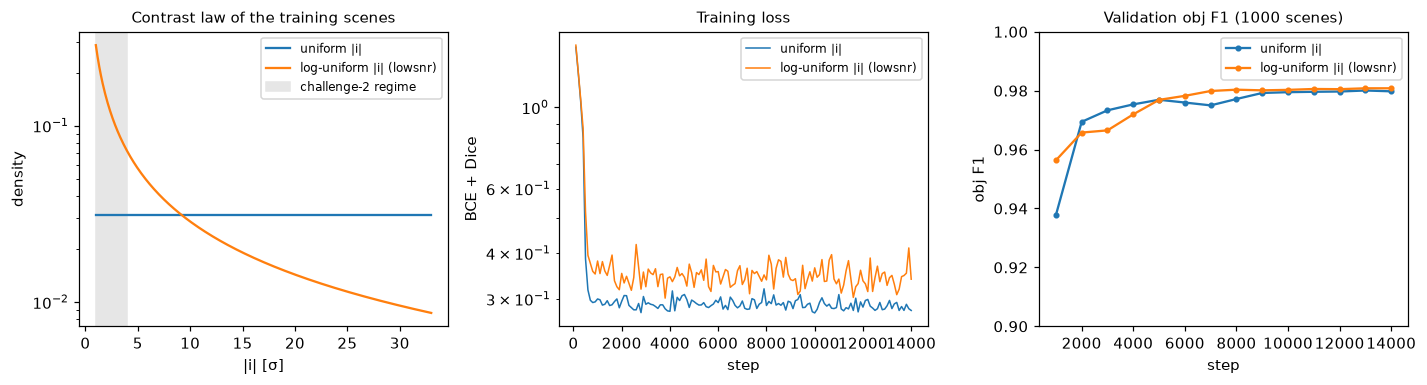

In [4]:
def jsonl(path):
    return [json.loads(l) for l in open(path)]


logs = {name: jsonl(RES / f"logs/{name}.jsonl") for name in ("unet", "unet_lowsnr")}
evals = {name: json.load(open(RES / f"logs/{name}_eval.json")) for name in logs}
label = {"unet": "uniform |i|", "unet_lowsnr": "log-uniform |i| (lowsnr)"}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
a = np.linspace(1, 33, 400)
axes[0].plot(a, np.full_like(a, 1 / 32), label=label["unet"])
axes[0].plot(a, 1 / (a * np.log(33)), label=label["unet_lowsnr"])
axes[0].axvspan(1, 4, color="0.9", label="challenge-2 regime")
axes[0].set(xlabel="|i| [σ]", ylabel="density", title="Contrast law of the training scenes", yscale="log")
axes[0].legend(fontsize=8)
for name, log in logs.items():
    tr = [r for r in log if "loss" in r]
    ev = [r for r in log if r.get("eval")]
    axes[1].plot([r["step"] for r in tr], [r["loss"] for r in tr], lw=1, label=label[name])
    axes[2].plot([r["step"] for r in ev], [r["val_obj_f1"] for r in ev], "o-", ms=3, label=label[name])
axes[1].set(xlabel="step", ylabel="BCE + Dice", title="Training loss", yscale="log")
axes[2].set(xlabel="step", ylabel="obj F1", title="Validation obj F1 (1000 scenes)", ylim=(0.9, 1))
for ax in axes[1:]:
    ax.legend(fontsize=8)
plt.tight_layout()

## 4. Result on the clean test

The frozen U-Net, run here on the 200 test scenes, with its val threshold. Green: predicted
pixels within ±1 px of a true one; red: false predictions; orange: missed stick pixels.

obj F1 0.980  (precision 0.996, recall 0.965)
tol F1 0.990   strict Dice 0.984


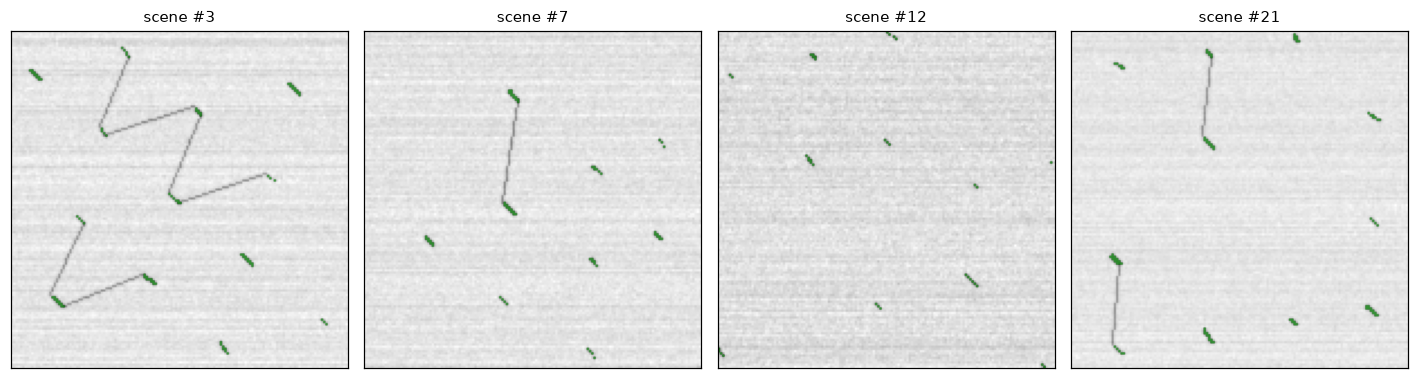

In [5]:
r = score(probs, test, thr=THR)
print(f"obj F1 {r['obj_f1']:.3f}  (precision {r['obj_precision']:.3f}, recall {r['obj_recall']:.3f})")
print(f"tol F1 {r['tol_f1']:.3f}   strict Dice {r['f1']:.3f}")

from scipy.ndimage import binary_dilation


def overlay(ax, img, pred, gt, title):
    near_gt = binary_dilation(gt, np.ones((3, 3)))
    near_pred = binary_dilation(pred, np.ones((3, 3)))
    panel(ax, img, title)
    for msk, col in ((pred & near_gt, "tab:green"), (pred & ~near_gt, "tab:red"), (gt & ~near_pred, "tab:orange")):
        ax.imshow(np.ma.masked_where(~msk, msk), cmap=ListedColormap([col]), alpha=0.8)


fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, k in zip(axes, (3, 7, 12, 21)):
    pred = probs[k].astype(np.float32) > THR
    overlay(ax, test.images[k], pred, test.masks[k].astype(bool), f"scene #{k}")
plt.tight_layout()

**Where the gain is.** Recall per contrast bin, on the 400-scene test set, for the uniform and
the log-uniform training laws. The log-uniform law buys recall exactly where challenge 2 lives
(2–4 σ) without losing anything above. On the 150 challenge-2 frames the U-Net reaches obj F1
0.96. Below 2 σ a stick is mostly invisible to any detector.

uniform |i|                test obj F1 0.978   challenge-2 frames obj F1 0.956
log-uniform |i| (lowsnr)   test obj F1 0.979   challenge-2 frames obj F1 0.964


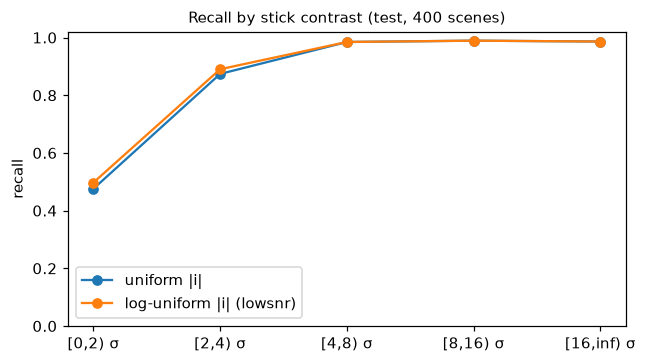

In [6]:
bins = list(evals["unet"]["sets"]["test"]["recall_by_amplitude"])
fig, ax = plt.subplots(figsize=(6, 3.4))
for name, ev in evals.items():
    rec = [ev["sets"]["test"]["recall_by_amplitude"][b][0] for b in bins]
    ax.plot(range(len(bins)), rec, "o-", label=label[name])
ax.set(xticks=range(len(bins)), xticklabels=[b + " σ" for b in bins], ylabel="recall", ylim=(0, 1.02),
       title="Recall by stick contrast (test, 400 scenes)")
ax.legend()
plt.tight_layout()
for name, ev in evals.items():
    s = ev["sets"]
    print(f"{label[name]:26s} test obj F1 {s['test']['obj_f1']:.3f}   challenge-2 frames obj F1 {s['ood_stage2']['obj_f1']:.3f}")

**Warning sign.** The strict Dice is ≈ 1: the network has learned the pixelization rule of the
generator. Excellent inside the simulator — and a hint that it is **specialized** to it.

## 5. Where the U-Net breaks: artefacts it has never seen

A real chip adds measurement artefacts the official generator never produces. The robustness
suite degrades the same 200 scenes with **one** artefact at a time: 9 families × up to 3 levels
= 25 sets (white and 1/f noise, drift, charge jumps, stripes, lock-in low-pass, saturation,
outlier pixels, inverted polarity). Masks are unchanged, so any drop is due to the artefact.

Three of them, generated and scored live:

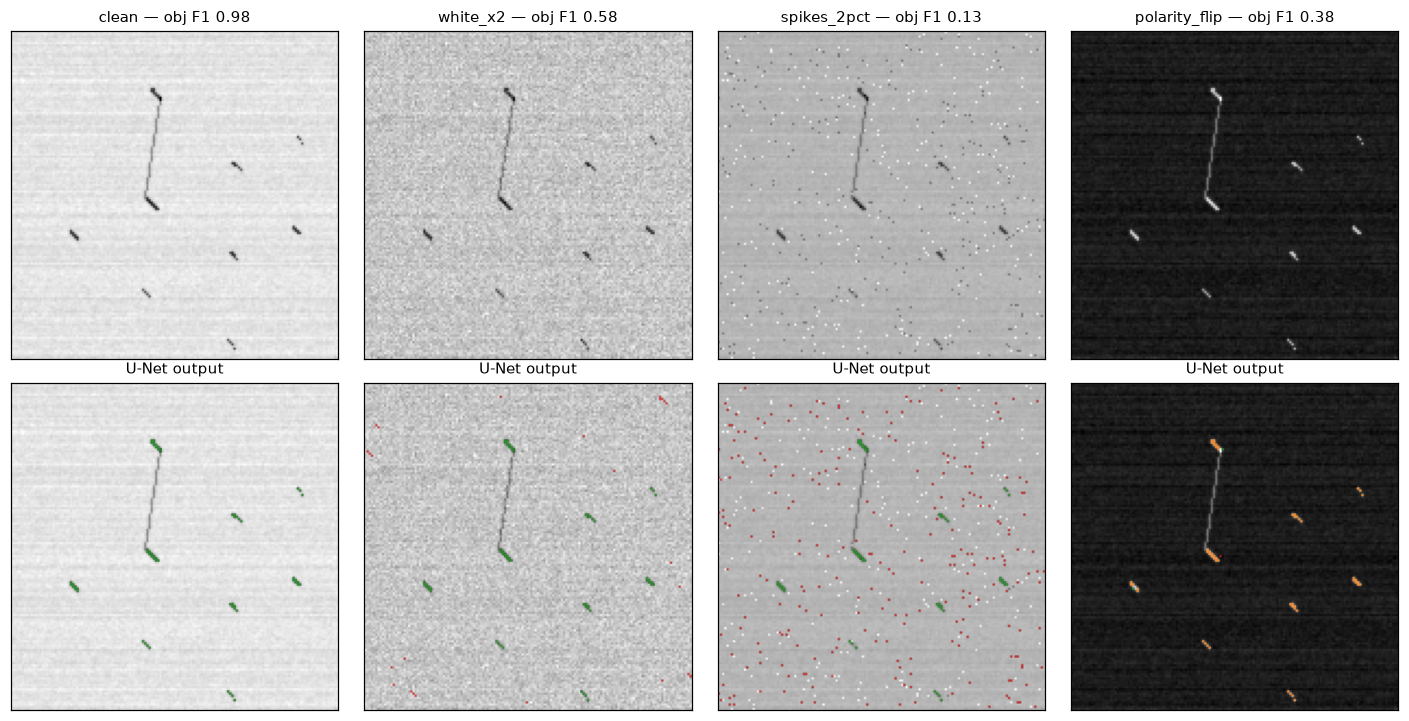

In [7]:
rng = np.random.default_rng(0)
cases = [("white", 2.0), ("spikes", 0.02), ("polarity", 1.0)]
pert = {(kind, lv): np.stack([perturb(x, kind, lv, rng) for x in test.images]).astype(np.float32) for kind, lv in cases}

k = 7
fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
gt = test.masks[k].astype(bool)
overlay(axes[1, 0], test.images[k], probs[k].astype(np.float32) > THR, gt, "U-Net output")
panel(axes[0, 0], test.images[k], f"clean — obj F1 {obj_f1(probs, test):.2f}")
for j, (kind, lv) in enumerate(cases, 1):
    imgs = pert[kind, lv]
    p = predict(unet, imgs, DEV)
    panel(axes[0, j], imgs[k], f"{set_name(kind, lv)} — obj F1 {obj_f1(p, Scenes(imgs, test.masks, sticks, kind)):.2f}")
    overlay(axes[1, j], imgs[k], p[k].astype(np.float32) > THR, gt, "U-Net output")
plt.tight_layout()

**Finding.** 2 % of outlier pixels or a doubled white noise make the U-Net invent and miss
sticks; with the sign inverted it no longer sees them at all. Over the 25 sets the
**robustness score** — mean of obj F1 (perturbed) / obj F1 (clean) — is **0.872**. The most
accurate model is not the most reliable one.

In [8]:
rob = json.load(open(RES / "robustness_dl_summary.json"))["fast_unet_lowsnr"]["sets"]
names = [set_name(f, lv) for f, lvs in LEVELS.items() for lv in lvs]
clean_ref = rob["clean"]["obj_f1"][0]
unet_set = {n: rob[n]["obj_f1"][0] for n in names}
print(f"U-Net robustness score: {np.mean([unet_set[n] / clean_ref for n in names]):.3f}")

U-Net robustness score: 0.872


## 6. The remedy: physical preprocessing + randomized artefacts

The architecture is untouched. Two changes:

- **`PhysInput`** (`detection/models.py`): a layer *without learned parameters* placed in front of
  the U-Net and kept at inference. It subtracts the median of each row (stripes, drift, jumps),
  rescales by the MAD (the input stays in noise σ), and **despikes**: a pixel above 6 σ whose 8
  neighbours stay weak cannot be a stick (a stick is ≥ 4 px long), so it is replaced by its 3 × 3
  median. Measured: 90 % of the ±10 spikes removed at low density, 0.4 % of stick pixels touched.
  At 2 % of pixels, neighbouring spikes start to hide each other (see the count below).
- **Randomized generator** (`detection/synth.py`, `--artifacts`): the 8 artefact families are
  drawn on the GPU, each with probability 0.2 and a uniform severity; polarity is augmented.

**Before / after `PhysInput`** on a scene with 2 % of spikes:

spikes still above 6 σ after PhysInput: 102 / 511


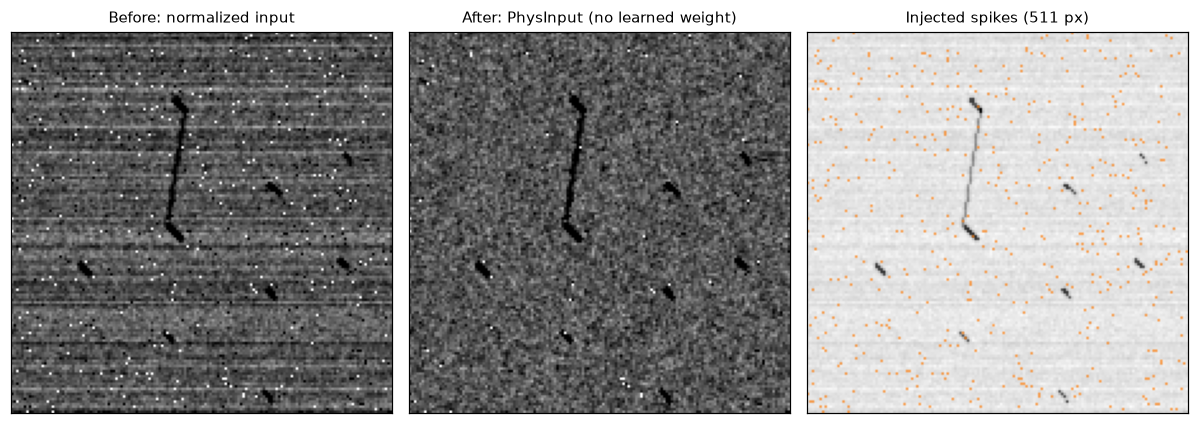

In [9]:
imgs = pert["spikes", 0.02]
x = torch.from_numpy(imgs[k : k + 1, None])
with torch.no_grad():
    from detection.synth import robust_normalize

    before = robust_normalize(x)[0, 0].numpy()
    after = PhysInput()(robust_normalize(x))[0, 0].numpy()
spikes = np.abs(imgs[k] - test.images[k]) > 5
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
kw = {"vmin": -3, "vmax": 6}
panel(axes[0], before, "Before: normalized input", **kw)
panel(axes[1], after, "After: PhysInput (no learned weight)", **kw)
panel(axes[2], test.images[k], f"Injected spikes ({spikes.sum()} px)", spikes, "tab:orange")
plt.tight_layout()
left = (np.abs(after) > 6) & spikes
print(f"spikes still above 6 σ after PhysInput: {left.sum()} / {spikes.sum()}")

## 7. The honest test: leave-one-family-out (LOFO)

Training on all families and testing on the same families only measures how well the suite was
learned. On a real chip there will always be an artefact nobody planned. So, for each family
*f*, a U-Net is trained **on every family except f** and scored **only on f**. Two references
with the same recipe bracket it:

| run | families seen in training | role |
|---|---|---|
| `none` | none (PhysInput only) | floor: what the preprocessing alone gives |
| **`no-f`** | all but *f* | **the question: f is unknown** |
| `all` | all, *f* included | ceiling: *f* is in the distribution |

Two capacities (0.5 M and 1.9 M parameters) × 11 runs = 22 runs of 8000 steps, thresholds on
val, the suite report-only. Below: obj F1 on each family, averaged over its levels.

family     transfer (LOFO-none)  gap (all-LOFO)   [1.9 M]
white                    +0.020          +0.009
pink                     -0.001          +0.000
drift                    -0.000          -0.002
jumps                    +0.011          +0.008
stripes                  -0.001          -0.002
lowpass                  +0.004          +0.012
saturate                 +0.000          -0.000
spikes                   +0.072          +0.195
polarity                 -0.872          +0.868


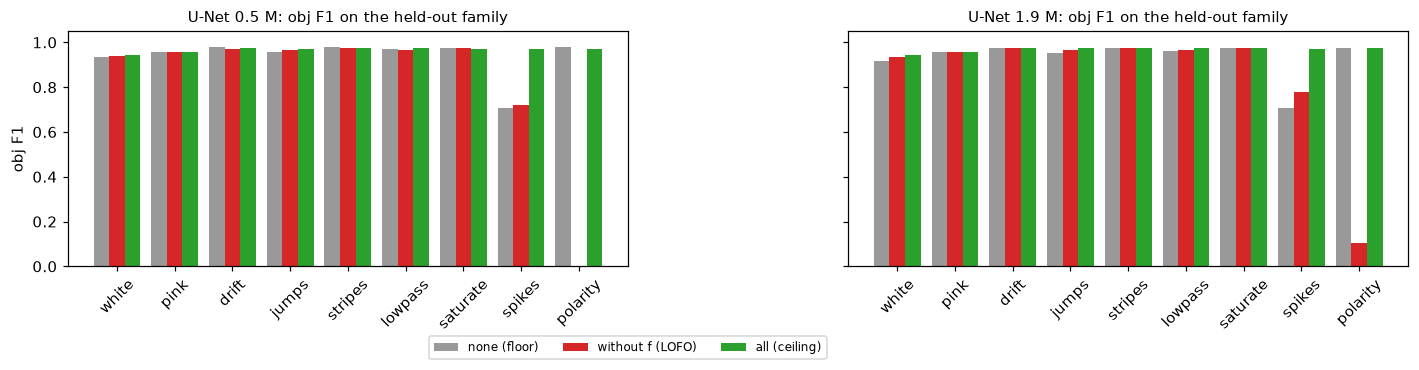

In [10]:
lofo = json.load(open(RES / "lofo/lofo.json"))["table"]
fams = [f for f in lofo if not f.startswith("_")]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, cap, title in zip(axes, ("u16", "u32"), ("U-Net 0.5 M", "U-Net 1.9 M")):
    x = np.arange(len(fams))
    for dx, run, col, lab in ((-0.27, "none", "0.6", "none (floor)"), (0, "lofo", "tab:red", "without f (LOFO)"),
                              (0.27, "all", "tab:green", "all (ceiling)")):
        ax.bar(x + dx, [lofo[f][cap][run][0] for f in fams], 0.27, color=col, label=lab)
    ax.set(xticks=x, xticklabels=fams, ylim=(0, 1.05), title=f"{title}: obj F1 on the held-out family")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("obj F1")
axes[0].legend(fontsize=8, loc="lower center", bbox_to_anchor=(1.0, -0.42), ncol=3)
plt.tight_layout()

print(f"{'family':9s} {'transfer (LOFO-none)':>21s} {'gap (all-LOFO)':>15s}   [1.9 M]")
for f in fams:
    t = lofo[f]["u32"]
    print(f"{f:9s} {t['lofo'][0] - t['none'][0]:+21.3f} {t['all'][0] - t['lofo'][0]:+15.3f}")

**Reading.**

1. **The physical preprocessing does most of the work.** With `PhysInput` alone (`none`), drift,
   stripes, saturation and 1/f noise are already at ≥ 0.956; learning them changes nothing.
2. **Families barely transfer.** LOFO − none stays under +0.02 everywhere, even between close
   families (white / pink). Randomization protects *what it covers*, not a new artefact.
3. **Two orthogonal families are catastrophic when unseen.** *Polarity*: the network learns the
   sign of the sticks and nothing else removes it (0.00–0.11). *Spikes*: 0.72–0.78 against 0.97
   when seen; despiking alone is not enough at 2 % of pixels.
4. **Capacity barely matters**: 0.5 M and 1.9 M score the same on the clean test.
5. **The cost is low**: randomizing the 8 families costs 0.003 obj F1 on the clean test.

## 8. U-Net vs U-Net LOFO

For the U-Net LOFO, each of the 25 perturbed sets is scored by the 1.9 M model **that never saw
its family**, so nothing is tuned to the sets it is graded on. Challenge-2 frames and empty
scenes: mean of the 9 LOFO runs, each with its own frozen val threshold.

In [11]:
lofo_set, lofo_clean = {}, {}
for f, lvs in LEVELS.items():
    ev = json.load(open(RES / f"lofo/per_run/lofo_u32_no-{f}/eval.json"))["sets"]
    for lv in lvs:
        n = set_name(f, lv)
        lofo_set[n], lofo_clean[n] = ev[n]["obj_f1"], ev["clean"]["obj_f1"]

c2 = {r["name"]: r for r in json.load(open(RES / "lofo/c2_null.json"))}
lofo_runs = [v for n, v in c2.items() if n.startswith("lofo_u32_no-")]


def robustness(per_set, clean, keep=lambda n: True):
    return np.mean([per_set[n] / clean[n] for n in names if keep(n)])


no_pol = lambda n: not n.startswith("polarity")
unet_clean = {n: clean_ref for n in names}
rows = {
    "obj F1, clean test (200 scenes)": (clean_ref, np.mean(list(lofo_clean.values()))),
    "obj F1, challenge-2 frames": (c2["unet_lowsnr"]["c2_obj_f1"], np.mean([r["c2_obj_f1"] for r in lofo_runs])),
    "false alarms per empty scene": (c2["unet_lowsnr"]["null_blobs_per_img"], np.mean([r["null_blobs_per_img"] for r in lofo_runs])),
    "mean obj F1 over the 25 sets": (np.mean(list(unet_set.values())), np.mean(list(lofo_set.values()))),
    "robustness score (25 sets)": (robustness(unet_set, unet_clean), robustness(lofo_set, lofo_clean)),
    "robustness score without polarity": (robustness(unet_set, unet_clean, no_pol), robustness(lofo_set, lofo_clean, no_pol)),
    "worst set": (min(unet_set.values()), min(lofo_set.values())),
}
print(f"{'':36s} {'U-Net':>8s} {'U-Net LOFO':>11s}")
for k_, (a_, b_) in rows.items():
    print(f"{k_:36s} {a_:8.3f} {b_:11.3f}")

                                        U-Net  U-Net LOFO
obj F1, clean test (200 scenes)         0.980       0.975
obj F1, challenge-2 frames              0.964       0.951
false alarms per empty scene            0.780       1.097
mean obj F1 over the 25 sets            0.855       0.907
robustness score (25 sets)              0.872       0.930
robustness score without polarity       0.892       0.964
worst set                               0.134       0.105


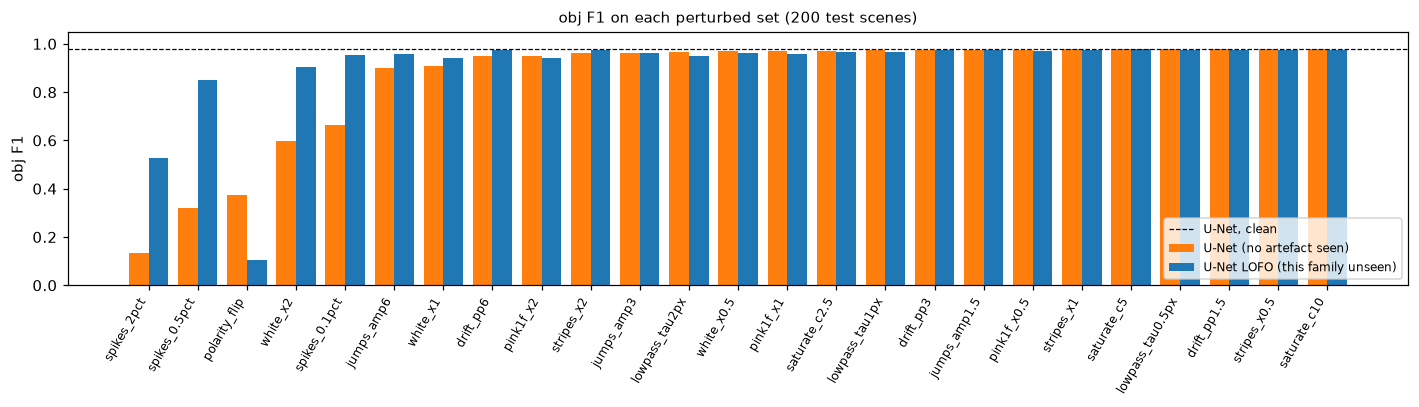

In [12]:
order = sorted(names, key=lambda n: unet_set[n])
fig, ax = plt.subplots(figsize=(13, 3.8))
x = np.arange(len(order))
ax.bar(x - 0.2, [unet_set[n] for n in order], 0.4, color="tab:orange", label="U-Net (no artefact seen)")
ax.bar(x + 0.2, [lofo_set[n] for n in order], 0.4, color="tab:blue", label="U-Net LOFO (this family unseen)")
ax.axhline(clean_ref, color="k", lw=0.8, ls="--", label="U-Net, clean")
ax.set(xticks=x, ylabel="obj F1", ylim=(0, 1.05), title="obj F1 on each perturbed set (200 test scenes)")
ax.set_xticklabels(order, rotation=60, ha="right", fontsize=8)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()

The U-Net LOFO keeps the accuracy of the plain U-Net (0.975 vs 0.980 on the clean scenes, 0.95
vs 0.96 on challenge-2 frames) and raises the robustness score from 0.872 to 0.930 although every
artefact was unknown to its scorer — 0.964 without polarity. White noise ×2 goes from 0.60 to
0.90. The price: more false alarms on empty scenes (1.10 vs 0.78 per scene).

## 9. Limitations and lessons

- **What is not randomized is not learned.** Known invariances must be imposed by construction
  (polarity fixed by the experimenter or always augmented; spikes despiked *and* seen in
  training), every plausible family covered, and a safeguard kept for the next unknown artefact.
- **One seed per run.** Differences of ~0.005 are not significant; the polarity and spike
  collapses are.
- **Everything is synthetic.** The artefacts are those we imagined, not those of a real chip.
- **False alarms.** 0.78 (U-Net) and 1.10 (U-Net LOFO) blobs per empty scene: when the detector
  is used as an objective in challenge 2, its threshold should be recalibrated on the
  false-alarm rate.

Reproduction commands (data generation, training, LOFO jobs): `stage1_unet/README.md`.